In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("..")

import ast
import json
from pathlib import Path
import numpy as np
import xarray as xr
import rioxarray as rxr
import pandas as pd
import regionmask
import ibicus
from ibicus.debias import QuantileMapping, ISIMIP

import xclim
from xclim import sdba

import rasterio
from rasterio.warp import transform

from dask.diagnostics import ProgressBar

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid", {"grid.color": ".93"})

from src.load_data import ClimateModelData, ClimateReanalysisData
from src.timesteps_adjustments import extract_adjusted_timesteps, get_new_timesteps
from src.utils_xarray import (
    xr_reorder_coords,
    get_time_resolution,
    get_specific_hourly_data,
    get_valid_hours,
    match_time_steps
)
from src.bias_correction_xclim import empirical_quantile_mapping, DICT_DEFAULT_XCLIM_PARAMETERS

In [3]:
paths = json.load(open("../paths.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_figs = Path(paths["path_figs"])

# Load climate model data

**CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1** simulation characteristics:
  * atransient aerosols
  * has wind speeds at multiple height levels
  * Lambert conformal conic projection in **km**

In [6]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

institute = climate_model_chain.split("-")[0]
rcm = climate_model_chain.split("_")[0]
gcm = climate_model_chain.split("_")[1]
ensemble = climate_model_chain.split("_")[-1]

## 1. Load linearized mapping of years to adjust warming trend of EURO-CORDEX model

In [6]:
df_climate_models_mapping = pd.read_csv(path_data_adjusted_cordex / "year_lists.csv")
df_climate_models_mapping["year_list"] = [ast.literal_eval(l) for l in df_climate_models_mapping["year_list"]]

adjusted_timesteps = extract_adjusted_timesteps(df_climate_models_mapping, climate_model_chain, climate_scenario)

## 2. Load climate data

In [51]:
variable = "tas"
temp_res = "3hr"

cordex_var = path_data_cordex / climate_scenario / temp_res / variable / institute / gcm / rcm / ensemble
cordex_var_hist = path_data_cordex / "historical" / temp_res / variable / institute / gcm / rcm / ensemble
cordex_processed_var = path_data_processed / "cordex-processed" / f"{climate_model_chain}_{climate_scenario}" / "raw" / f"{variable}_ch.nc"

In [8]:
rds = xr.open_dataset(list(cordex_var.glob("*"))[0])

In [52]:
climate_data = ClimateModelData(cordex_processed_var, chunks=None, load=True)

In [53]:
climate_data.ds_data

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 318496, lat: 30, lon: 50)
Coordinates:
  * time     (time) datetime64[ns] 3MB 1991-01-01 ... 2099-12-31T21:00:00
  * lon      (lon) float64 400B 5.85 5.95 6.05 6.15 ... 10.45 10.55 10.65 10.75
  * lat      (lat) float64 240B 45.05 45.15 45.25 45.35 ... 47.75 47.85 47.95
    height   (time) float64 3MB 2.0 2.0 2.0 2.0 2.0 ... 10.0 10.0 10.0 10.0 10.0
Data variables:
    tas      (time, lat, lon) float32 2GB 271.3 269.4 268.5 ... 276.8 276.6
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.2.1 (htt...
    Conventions:                    CF-1.6
    institution:                    CNRM (Centre National de Recherches Meteo...
    description:                    Created by xios
    title:                          Created by xios
    creation_date:                  2018-10-19T08:40:28Z
    ...                             ...
    comment:                        CORDEX Europe EUR-11 CNRM-ALADIN 6.3 L91 ...
    c3s_disclaimer:                 This data has been produced in the contex...
    driving_experiment_comment:     Known issue correction: this simulation (...
    frequency:                      3hr
    history:                        Fri Jan 24 11:42:58 2025: cdo remapcon,/l...
    CDO:                            Climate Data Operators version 2.2.0 (htt...

<Axes: title={'center': 'time = 1991-01-01, height = 2.0 [m]'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

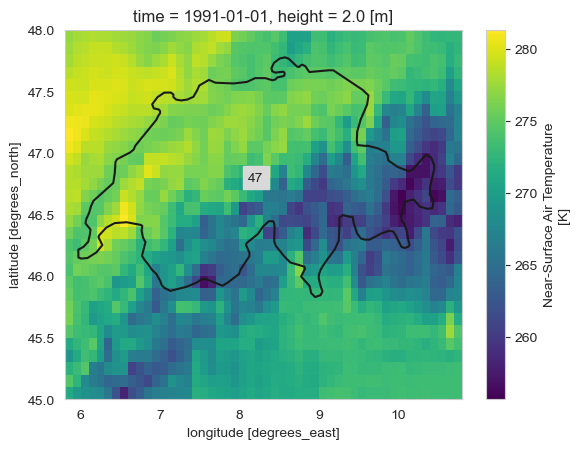

In [54]:
climate_data.ds_data.isel(time=0)['tas'].plot(x='lon', y='lat')

regionmask.defined_regions.natural_earth_v5_0_0.countries_50[['Switzerland']].plot_regions()

In [57]:
climate_data.ds_data

<xarray.Dataset> Size: 2GB
Dimensions:  (time: 318496, lat: 30, lon: 50)
Coordinates:
  * time     (time) datetime64[ns] 3MB 1991-01-01 ... 2099-12-31T21:00:00
  * lon      (lon) float64 400B 5.85 5.95 6.05 6.15 ... 10.45 10.55 10.65 10.75
  * lat      (lat) float64 240B 45.05 45.15 45.25 45.35 ... 47.75 47.85 47.95
    height   (time) float64 3MB 2.0 2.0 2.0 2.0 2.0 ... 10.0 10.0 10.0 10.0 10.0
Data variables:
    tas      (time, lat, lon) float32 2GB 271.3 269.4 268.5 ... 276.8 276.6
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.2.1 (htt...
    Conventions:                    CF-1.6
    institution:                    CNRM (Centre National de Recherches Meteo...
    description:                    Created by xios
    title:                          Created by xios
    creation_date:                  2018-10-19T08:40:28Z
    ...                             ...
    comment:                        CORDEX Europe EUR-11 CNRM-ALADIN 6.3 L91 ...
    c3s_disclaimer:                 This data has been produced in the contex...
    driving_experiment_comment:     Known issue correction: this simulation (...
    frequency:                      3hr
    history:                        Fri Jan 24 11:42:58 2025: cdo remapcon,/l...
    CDO:                            Climate Data Operators version 2.2.0 (htt...

In [14]:
variables = ["tas", "pr", "rsds", "sfcWind", "huss"]
climate_data_dict = {}

for variable in variables:
    cordex_processed_var = path_data_processed / "cordex-processed" / f"{climate_model_chain}_{climate_scenario}" / "raw" / f"{variable}_ch.nc"
    climate_data_dict[variable] = ClimateModelData(cordex_processed_var, chunks=None, load=True)

## 3. Plot general plots

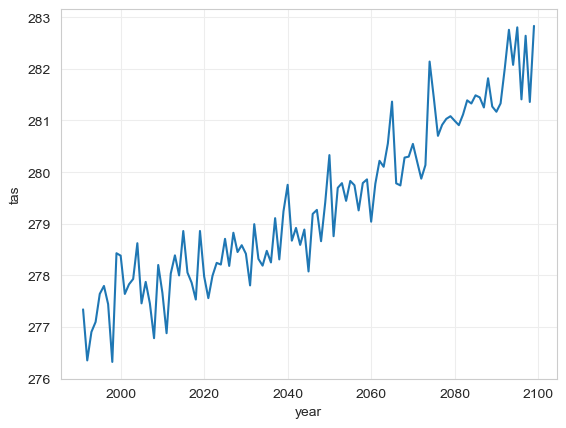

In [88]:
climate_data.plot_annual_mean("tas", spatial_mean=True)

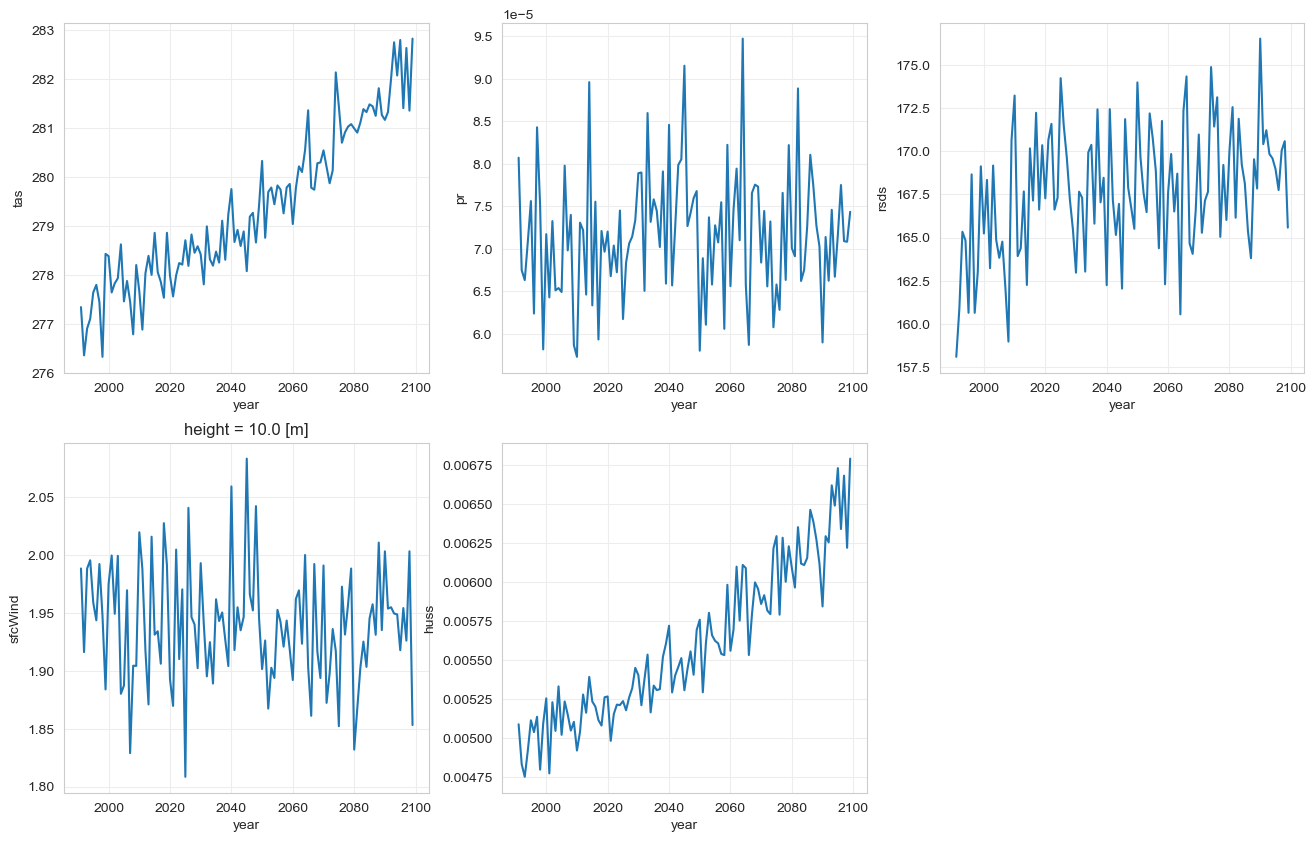

In [91]:
fig, ax = plt.subplots(2, 3, figsize=(16, 10))
ax = ax.flatten()
for i, variable in enumerate(climate_data_dict):
    climate_data_dict[variable].plot_annual_mean(variable, spatial_mean=True, ax=ax[i])

ax[-1].axis("off")
plt.show()

# Load reanalysis data

In [109]:
variable = "tp"
cerra_var = path_data_cerra / "original" / variable

In [123]:
ds_reanalysis_data = xr.open_dataset(cerra_var / "2t_3hr_cerra_1985.nc").sortby("time")

In [124]:
ds_reanalysis_data

<xarray.Dataset> Size: 239GB
Dimensions:  (time: 107616, lat: 507, lon: 1096)
Coordinates:
  * time     (time) datetime64[ns] 861kB 1984-09-01 ... 2021-06-30T21:00:00
  * lon      (lon) float64 9kB -44.55 -44.45 -44.35 -44.25 ... 64.75 64.85 64.95
  * lat      (lat) float64 4kB 21.95 22.05 22.15 22.25 ... 72.35 72.45 72.55
Data variables:
    tp       (time, lat, lon) float32 239GB dask.array<chunksize=(100, 507, 1096), meta=np.ndarray>
Attributes:
    CDI:          Climate Data Interface version 2.2.1 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Mon Feb 03 17:18:40 2025: cdo remapcon,/landclim/yhaddad/cl...
    CDO:          Climate Data Operators version 2.2.0 (https://mpimet.mpg.de...

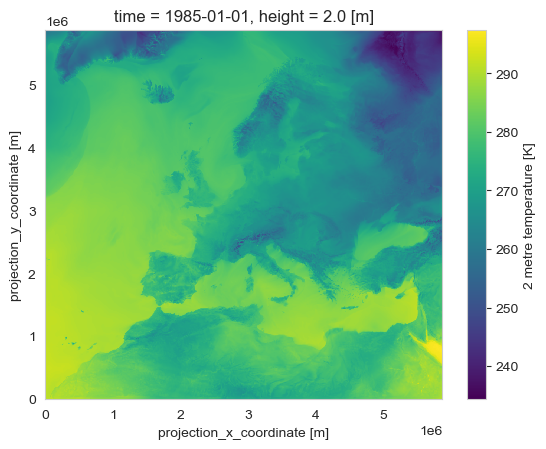

In [18]:
ds_reanalysis_data["2t"].isel(time=0).plot()

# Load regridded climate model and reanalysis data

In [11]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"
cordex_var = "tas"
regridded_cordex_var_path = path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded"

cerra_var = "2t"
regridded_cerra_var_path = path_data_processed / "cerra_processed" / "regridded"

In [12]:
chunks = {"time": 500, "lat": 256, "lon": 256}
ds_climate_model_data = xr.open_zarr(regridded_cordex_var_path / f"{cordex_var}.zarr").chunk(chunks=chunks)
ds_reanalysis_data = xr.open_zarr(regridded_cerra_var_path / f"{cerra_var}.zarr").chunk(chunks=chunks)

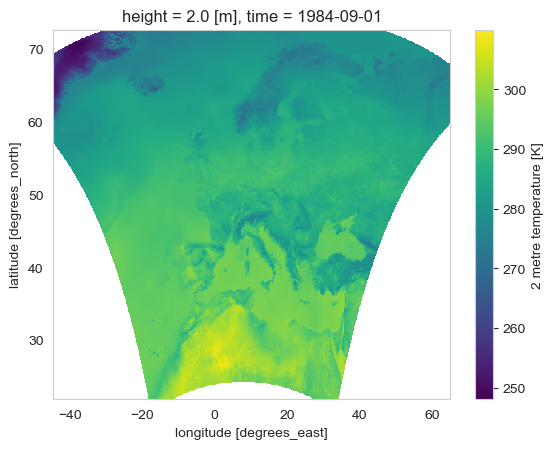

In [13]:
ds_reanalysis_data.isel(time=0)["2t"].plot()

# Debias climate model simulation

## Test different bias correction methods

In [16]:
lat_extent = [45.8, 47.9]
lon_extent = [5.9, 10.5]
ds_reanalysis_data = ds_reanalysis_data.sel(time=slice("1991", "2020")).isel(height=0).sel(lat=slice(*lat_extent), lon=slice(*lon_extent)).rename({"lat": "y", "lon": "x"})
ds_climate_model_data_ch_past = ds_climate_model_data.sel(time=slice("1991", "2020")).sel(lat=slice(*lat_extent), lon=slice(*lon_extent)).rename({"lat": "y", "lon": "x"})
ds_climate_model_data_ch_future = ds_climate_model_data.sel(time=slice("2021", None)).sel(lat=slice(*lat_extent), lon=slice(*lon_extent)).rename({"lat": "y", "lon": "x"})

In [20]:
debiaser = QuantileMapping.from_variable("tas", running_window_mode=True, running_window_length=91)

debiased_cm_future_cerra = debiaser.apply(ds_reanalysis_data_ch.sel(time=ds_reanalysis_data_ch.time.dt.hour == 3)["2t"].values, 
                                          ds_climate_model_data_ch_past.sel(time=ds_climate_model_data_ch_past.time.dt.hour == 3)["tas"].values, 
                                          ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3)["tas"].values)

  0%|          | 0/966 [00:00<?, ?it/s]/home/yhaddad/.conda/envs/bias_correction_2023/lib/python3.11/site-packages/ibicus/debias/_debiaser.py:387: UserWarning: Debiaser runs without time-information for at least one of obs, cm_hist or cm_future.
                        This information is inferred, assuming the first observation is on a January 1st. Observations are chunked according to the assumed time information.
                        This might lead to slight numerical differences to the run with time information, however the debiasing is not fundamentally changed.
  return func(obs, cm_hist, cm_future, **kwargs)
100%|██████████| 966/966 [09:11<00:00,  1.75it/s]


In [22]:
ds_climate_model_data_ch_future_debiased = ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3).copy(data={"tas": debiased_cm_future_cerra})

In [23]:
ds_climate_model_data_ch_future_debiased

<xarray.Dataset> Size: 112MB
Dimensions:  (time: 28854, y: 21, x: 46)
Coordinates:
    height   (time) float64 231kB dask.array<chunksize=(42,), meta=np.ndarray>
  * y        (y) float64 168B 45.85 45.95 46.05 46.15 ... 47.65 47.75 47.85
  * x        (x) float64 368B 5.95 6.05 6.15 6.25 ... 10.15 10.25 10.35 10.45
  * time     (time) datetime64[ns] 231kB 2021-01-01T03:00:00 ... 2099-12-31T0...
Data variables:
    tas      (time, y, x) float32 111MB 274.8 274.5 274.6 ... 279.0 278.7 278.3
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.2.1 (htt...
    CDO:                            Climate Data Operators version 2.2.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/b5f438d4-cd97-40cf-b3d7-6c05...

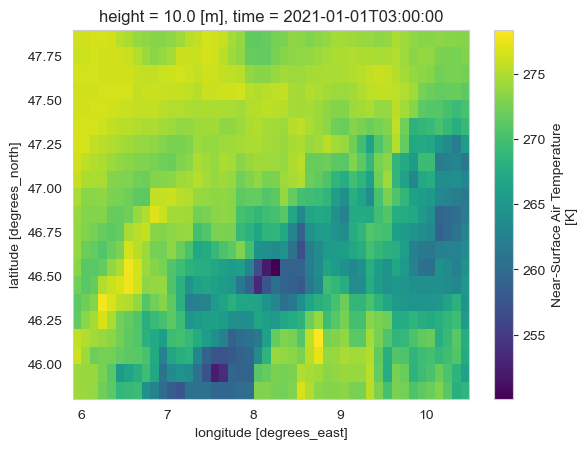

In [24]:
ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3).isel(time=0).tas.plot()

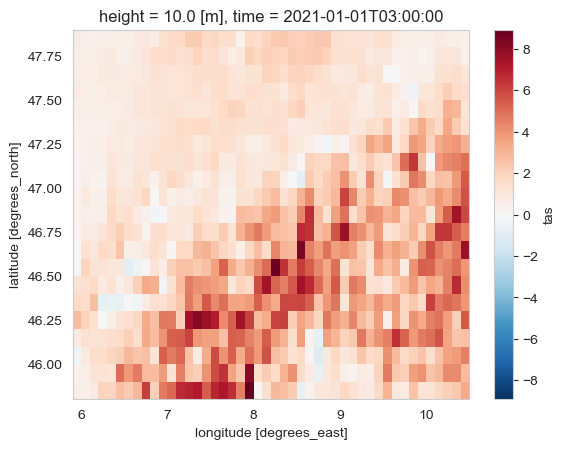

In [25]:
(ds_climate_model_data_ch_future_debiased.isel(time=0) - ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3).isel(time=0)).tas.plot()

In [26]:
debiaser_qm = QuantileMapping(running_window_mode=True, running_window_length=91)

debiased_cm_future_cerra_qm = debiaser_qm.apply(ds_reanalysis_data_ch.sel(time=ds_reanalysis_data_ch.time.dt.hour == 3)["2t"].values, 
                                          ds_climate_model_data_ch_past.sel(time=ds_climate_model_data_ch_past.time.dt.hour == 3)["tas"].values, 
                                          ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3)["tas"].values)

  0%|          | 0/966 [00:00<?, ?it/s]/home/yhaddad/.conda/envs/bias_correction_2023/lib/python3.11/site-packages/ibicus/debias/_debiaser.py:387: UserWarning: Debiaser runs without time-information for at least one of obs, cm_hist or cm_future.
                        This information is inferred, assuming the first observation is on a January 1st. Observations are chunked according to the assumed time information.
                        This might lead to slight numerical differences to the run with time information, however the debiasing is not fundamentally changed.
  return func(obs, cm_hist, cm_future, **kwargs)
100%|██████████| 966/966 [09:10<00:00,  1.76it/s]


In [225]:
tas_debiaser_ISIMIP = ISIMIP.from_variable("tas")

debiased_cm_future_cerra_ISIMIP = tas_debiaser_ISIMIP.apply(ds_reanalysis_data_ch.sel(time=ds_reanalysis_data_ch.time.dt.hour == 3)["2t"].values, 
                                          ds_climate_model_data_ch_past.sel(time=ds_climate_model_data_ch_past.time.dt.hour == 3)["tas"].values, 
                                          ds_climate_model_data_ch_future.sel(time=ds_climate_model_data_ch_future.time.dt.hour == 3)["tas"].values)

  0%|          | 0/966 [00:00<?, ?it/s]/home/yhaddad/.conda/envs/bias_correction_2023/lib/python3.11/site-packages/ibicus/debias/_debiaser.py:387: UserWarning: ISIMIP runs without time-information for at least one of obs, cm_hist or cm_future.
                    This information is inferred, assuming the first observation is on a January 1st. Observations are chunked according to the assumed time information.
                    This might lead to slight numerical differences to the run with time information, however the debiasing is not fundamentally changed.
  return func(obs, cm_hist, cm_future, **kwargs)
100%|██████████| 966/966 [1:17:28<00:00,  4.81s/it]


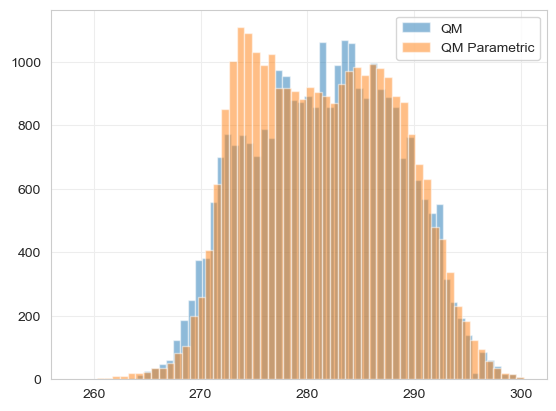

In [27]:
plt.hist(debiased_cm_future_cerra_qm[:, 1, 1], bins="auto", alpha = 0.5, label = "QM")
plt.hist(debiased_cm_future_cerra[:, 1, 1], bins="auto", alpha = 0.5, label = "QM Parametric")
# plt.hist(debiased_cm_future_cerra_ISIMIP[:, 1, 1], bins="auto", alpha = 0.5, label = "ISIMIP")
plt.legend()
plt.show()

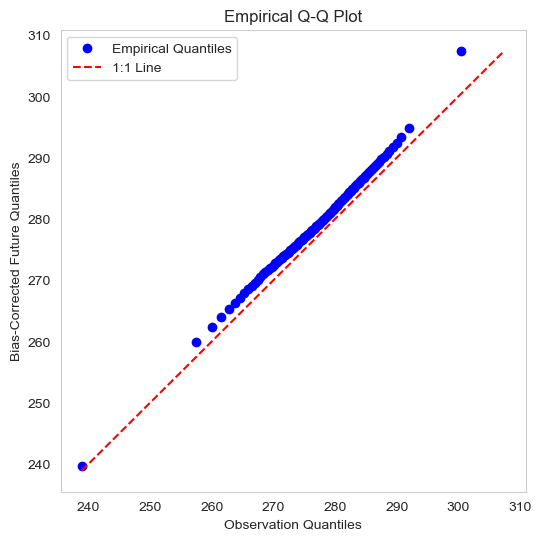

In [35]:
import numpy as np
import matplotlib.pyplot as plt

def plot_empirical_qq(obs, fut_corrected):
    """
    Plots an empirical Q-Q plot comparing bias-corrected future projections against observations.
    
    Parameters:
        obs (xarray.DataArray): Observational dataset.
        fut_corrected (xarray.DataArray): Bias-corrected future dataset.
        var_name (str): Name of the variable to compare.
    """
    # Flatten and remove NaNs
    obs_data = obs.flatten()
    fut_data = fut_corrected.flatten()
    
    obs_data = obs_data[~np.isnan(obs_data)]
    fut_data = fut_data[~np.isnan(fut_data)]

    # Compute empirical quantiles (percentiles)
    quantiles = np.linspace(0, 100, num=100)  # 100 percentiles
    obs_quantiles = np.percentile(obs_data, quantiles)
    fut_quantiles = np.percentile(fut_data, quantiles)

    # Plot Q-Q plot
    plt.figure(figsize=(6, 6))
    plt.scatter(obs_quantiles, fut_quantiles, color="blue", label="Empirical Quantiles")
    
    # Add 1:1 reference line
    min_val = min(obs_quantiles.min(), fut_quantiles.min())
    max_val = max(obs_quantiles.max(), fut_quantiles.max())
    plt.plot([min_val, max_val], [min_val, max_val], linestyle="--", color="red", label="1:1 Line")

    # Customize plot
    plt.xlabel("Observation Quantiles")
    plt.ylabel("Bias-Corrected Future Quantiles")
    plt.title(f"Empirical Q-Q Plot")
    plt.legend()
    plt.grid()

    # Show plot
    plt.show()

# Example usage:
plot_empirical_qq(ds_reanalysis_data_ch.sel(time=ds_reanalysis_data_ch.time.dt.hour == 3)["2t"].values, debiased_cm_future_cerra)

## Application of pipeline

In [7]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"
cordex_var = "tas"
temp_res = "3hr"
regridded_cordex_var_path = path_data_processed / "cordex_processed" / f"{climate_model_chain}_{climate_scenario}" / "regridded" / temp_res

cerra_var = "2t"
regridded_cerra_var_path = path_data_processed / "cerra_processed" / "regridded"

### ibicus

In [69]:
chunks = {"time": 500, "lat": 256, "lon": 256}
extent = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}
# extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
climate_data = ClimateModelData(regridded_cordex_var_path / f"{cordex_var}.zarr", chunks=chunks, extent=extent, load=False)
# climate_data.ds_data = get_specific_hourly_data(climate_data.ds_data, 0)
reanalysis_data = ClimateReanalysisData(regridded_cerra_var_path / f"{cerra_var}.zarr", chunks=chunks, extent=extent, load=False)
# reanalysis_data.ds_data = get_specific_hourly_data(reanalysis_data.ds_data, 0).isel(height=0)
reanalysis_data.ds_data = reanalysis_data.ds_data / (60 * 60 * 24)

In [71]:
%%time
ds_bc = climate_data.bias_correction(
    reanalysis_data.ds_data.rename({cerra_var: cordex_var}), 
    data_var=cordex_var,
    reference_period=("1991", "2017"),
    future_period=("2018", "2100"),
    bias_correction_method="quantile_mapping",
    parametric_existing_settings=True,
    running_window_mode=True,
    running_window_length=91,
    parallel=True,
    nr_processes=10,
    print_time=True
)

Adjusting time steps of the reference dataset


/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/ibicus/debias/_debiaser.py:538: UserWarning: progressbar argument is ignored when parallel = True.
  warnings.warn("progressbar argument is ignored when parallel = True.")
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/ibicus/debias/_debiaser.py:387: UserWarning: Debiaser runs without time-information for at least one of obs, cm_hist or cm_future.
                        This information is inferred, assuming the first observation is on a January 1st. Observations are chunked according to the assumed time information.
                        This might lead to slight numerical differences to the run with time information, however the debiasing is not fundamentally changed.
  return func(obs, cm_hist, cm_future, **kwargs)
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/ibicus/debias/_debiaser.py:387: UserWarning: Debiaser runs without time-information for 

	Time: 5.93 min
CPU times: user 1min 1s, sys: 2min 17s, total: 3min 19s
Wall time: 5min 56s


### Xclim bias correction

In [8]:
chunks = {"time": 500, "lat": 256, "lon": 256}
# chunks = {"time": -1, "lat": 60, "lon": 60}
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}
# extent = {"lat_min": 45.8, "lat_max": 47.9, "lon_min": 5.9, "lon_max": 10.5}
climate_data = ClimateModelData(regridded_cordex_var_path / f"{cordex_var}.zarr", chunks=chunks, extent=extent, load=False)
reanalysis_data = ClimateReanalysisData(regridded_cerra_var_path / f"{cerra_var}.zarr", chunks=chunks, extent=extent, load=False)

In [16]:
reference_period=("1991", "2017")
future_period=("2018", "2100")
data_var = "tas"


reanalysis_data.ds_data = reanalysis_data.ds_data.sel(height=2).drop_vars("height")
if (
    "height" in climate_data.ds_data.data_vars
    and "height" not in climate_data.ds_data[args.variable].dims
):
    climate_data.ds_data = climate_data.ds_data.drop_vars("height")
ds_reference = reanalysis_data.ds_data.rename({cerra_var: data_var})

time_res = get_time_resolution(climate_data.ds_data)
time_res_ref = get_time_resolution(ds_reference)
if time_res != time_res_ref:
    raise ValueError(
        "The time resolution of the climate model data and the reference data must be the same."
    )

first_time_step = pd.to_datetime(climate_data.ds_data.time.values[0])
# Check if the time steps are the same, if not, adjust the time steps of the reference dataset
ds_reference = match_time_steps(
    climate_data.ds_data, ds_reference, time_res, skip_leap_days=climate_data.drop_leap_days
)

if time_res < pd.Timedelta(days=1):
    hours = get_valid_hours(time_res, first_time_step.hour)
else:
    hours = []

# Select the data for the reference and future periods
da_reference_data = ds_reference.sel(time=slice(*reference_period))[data_var]
da_climate_model_data_past = climate_data.ds_data.sel(time=slice(*reference_period))[
    data_var
]
da_climate_model_data_future = climate_data.ds_data.sel(time=slice(*future_period))[
    data_var
        ]

In [ ]:
hour = 0
running_window_length=91
param_var = "sfcWind" if data_var.startswith("wind") else data_var
params = (
    DICT_DEFAULT_XCLIM_PARAMETERS[param_var]
)
with ProgressBar(dt=10):
    get_specific_hourly_data(da_climate_model_data_future, hour).copy(
        data=empirical_quantile_mapping(
            get_specific_hourly_data(da_climate_model_data_past, hour).load(),
            get_specific_hourly_data(
                da_climate_model_data_future, hour
            ).load(),
            get_specific_hourly_data(da_reference_data, hour).load(),
            window_length=running_window_length,
            **params
        ).compute())

[########################################] | 100% Completed | 10.06 s
[########################################] | 100% Completed | 30.05 s
[########################################] | 100% Completed | 10.07 s


#### tas

In [ ]:
da_reanalysis_data = get_specific_hourly_data(reanalysis_data.ds_data.sel(time=slice("1991", "2017")).isel(height=0), 0).rename({cerra_var: cordex_var})[cordex_var].chunk({"time": -1, "lat": 60, "lon": 60})
da_climate_model_data_ch_past = get_specific_hourly_data(climate_data.ds_data.sel(time=slice("1991", "2017")), 0)[cordex_var].drop_vars("height").chunk({"time": -1, "lat": 60, "lon": 60})
da_climate_model_data_ch_future = get_specific_hourly_data(climate_data.ds_data.sel(time=slice("2018", None)), 0)[cordex_var].drop_vars("height").chunk({"time": -1, "lat": 60, "lon": 60})

In [7]:
da_reanalysis_data = get_specific_hourly_data(reanalysis_data.ds_data.sel(time=slice("1991", "2017")).isel(height=0), 0).rename({cerra_var: cordex_var})[cordex_var]
da_climate_model_data_ch_past = get_specific_hourly_data(climate_data.ds_data.sel(time=slice("1991", "2017")), 0)[cordex_var].drop_vars("height")
da_climate_model_data_ch_future = get_specific_hourly_data(climate_data.ds_data.sel(time=slice("2018", None)), 0)[cordex_var].drop_vars("height")

In [7]:
# ds_reanalysis_data = get_specific_hourly_data(reanalysis_data.ds_data.sel(time=slice("1991", "2017")).isel(height=0), 0).rename({"2t": "tas"})["tas"].chunk({"time": -1, "lat": 1, "lon": 1})
# ds_climate_model_data_ch_past = get_specific_hourly_data(climate_data.ds_data.sel(time=slice("1991", "2017")), 0)["tas"].drop_vars("height").chunk({"time": -1, "lat": 1, "lon": 1})
# ds_climate_model_data_ch_future = get_specific_hourly_data(climate_data.ds_data.sel(time=slice("2018", None)), 0)["tas"].drop_vars("height").chunk({"time": -1, "lat": 1, "lon": 1})

In [8]:
# %%time
# ds_reanalysis_data = get_specific_hourly_data(reanalysis_data.ds_data.sel(time=slice("1991", "2017")).isel(height=0), 0).rename({cerra_var: cordex_var})[cordex_var].load()
# ds_climate_model_data_ch_past = get_specific_hourly_data(climate_data.ds_data.sel(time=slice("1991", "2017")), 0)[cordex_var].drop_vars("height").load()
# ds_climate_model_data_ch_future = get_specific_hourly_data(climate_data.ds_data.sel(time=slice("2018", None)), 0)[cordex_var].drop_vars("height").load()

#### pr

In [ ]:
%%time
da_reanalysis_data = reanalysis_data.ds_data.sel(time=slice("1991", "2017")).rename({cerra_var: cordex_var})[cordex_var].load()
da_climate_model_data_ch_past = climate_data.ds_data.sel(time=slice("1991", "2017"))[cordex_var].load()
da_climate_model_data_ch_future = climate_data.ds_data.sel(time=slice("2018", None))[cordex_var].load()

da_reanalysis_data.attrs.update({"units": "mm d-1"})

da_climate_model_data_ch_past = (da_climate_model_data_ch_past * 60 * 60 * 24)
da_climate_model_data_ch_past.attrs.update({"units": "mm d-1"})

da_climate_model_data_ch_future = (da_climate_model_data_ch_future * 60 * 60 * 24)
da_climate_model_data_ch_future.attrs.update({"units": "mm d-1"})

time_res = get_time_resolution(da_climate_model_data_ch_past)
first_time_step = pd.to_datetime(da_climate_model_data_ch_past.time.values[0])
if not np.array_equal(
    np.unique(da_climate_model_data_ch_past.time.dt.hour), np.unique(da_reanalysis_data.time.dt.hour)
):
    print("Adjusting time steps of the reference dataset")
    original_length = len(da_reanalysis_data.time)
    start_date = pd.to_datetime(da_reanalysis_data.time.values[0]).replace(
        hour=first_time_step.hour, minute=first_time_step.minute
    )
    new_time = []
    current_date = start_date
    while len(new_time) < original_length:
        if not (current_date.month == 2 and current_date.day == 29):
            new_time.append(current_date)
        current_date += pd.to_timedelta(time_res)
    da_reanalysis_data = da_reanalysis_data.assign_coords(time=new_time)

#### Run bias correction

In [151]:
%%time
ds_bc_xclim = empirical_quantile_mapping(da_climate_model_data_ch_past, da_climate_model_data_ch_future, da_reanalysis_data, window_length=91, **DICT_DEFAULT_XCLIM_PARAMETERS[cordex_var])

CPU times: user 19min 4s, sys: 6.02 s, total: 19min 10s
Wall time: 12min 43s


#### Run bias correction with dask

In [ ]:
# from dask.distributed import Client
# client = Client(processes=True, n_workers=10)  # 10 workers (1 per core)
import dask
dask.config.set(num_workers=20, scheduler='processes')

In [ ]:
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)

In [ ]:
client.shutdown()

In [ ]:
from dask import compute
from dask.diagnostics import ProgressBar
from dask.distributed import progress

group = sdba.Grouper("time.dayofyear", window=91)

QM = sdba.EmpiricalQuantileMapping.train(
    da_reanalysis_data, da_climate_model_data_ch_past, nquantiles=99, group=group, kind="+"
)
scen = QM.adjust(da_climate_model_data_ch_future, extrapolation="constant", interp="linear")

# with ProgressBar():
scen.compute()

### tas bias correction comparison

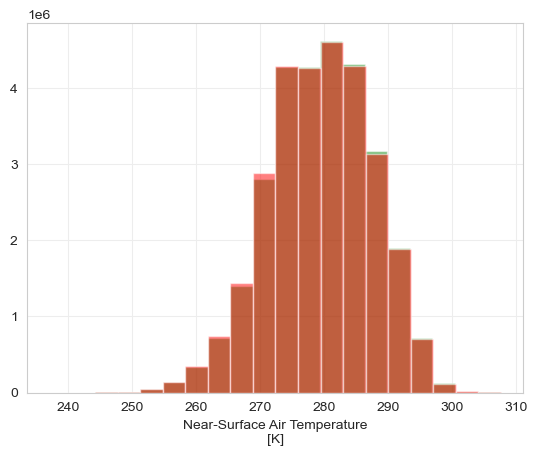

In [65]:
scen.transpose("time", "lat", "lon").scen.plot(bins=20, alpha=0.5, color="green")
ds_tas_bc.plot(bins=20, alpha=0.5, color="red")
plt.show()

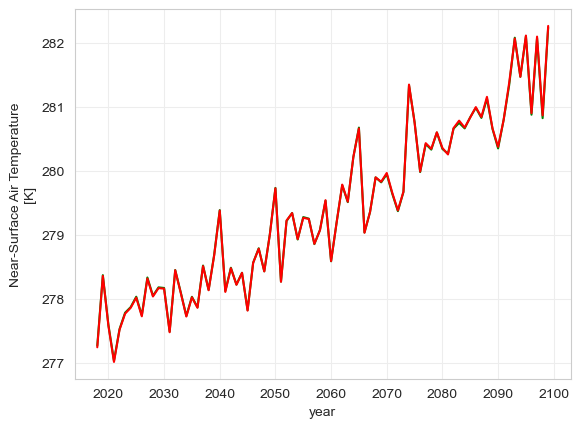

In [66]:
scen.transpose("time", "lat", "lon").scen.groupby("time.year").mean().mean(["lat", "lon"]).plot(color="green")
ds_tas_bc.groupby("time.year").mean().mean(["lat", "lon"]).plot(color="red")
plt.show()

### pr bias correction comparison

**Quantiles**

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


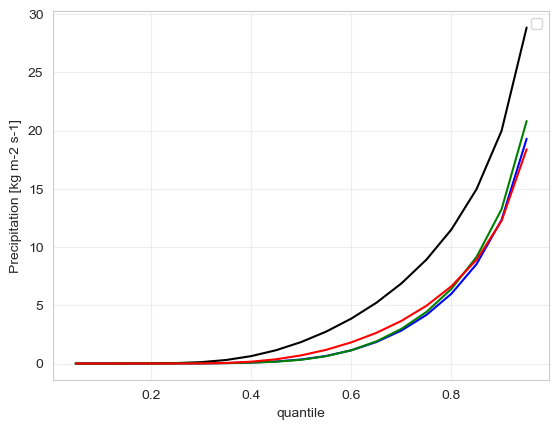

In [178]:
quantiles = np.arange(0.05, 1, 0.05)
da_reanalysis_data.quantile(quantiles).plot(color="blue")
da_climate_model_data_ch_future.quantile(quantiles).plot(color="black")
ds_bc_xclim.quantile(quantiles).plot(color="green")
(ds_bc * 86400).quantile(quantiles).plot(color="red")
plt.legend()
plt.show()

**Dry-day frequency**

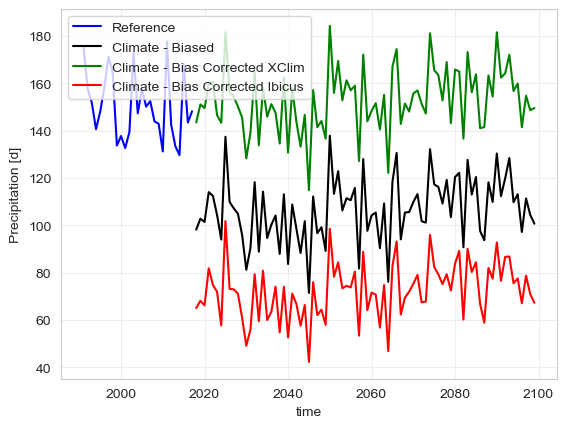

In [176]:
xclim.indices.dry_days(da_reanalysis_data, thresh='0.1 mm/d', freq='YS', op='<').mean(["lat", "lon"]).plot(color="blue", label="Reference")
xclim.indices.dry_days(da_climate_model_data_ch_future, thresh='0.1 mm/d', freq='YS', op='<').mean(["lat", "lon"]).plot(color="black", label="Climate - Biased")
xclim.indices.dry_days(ds_bc_xclim, thresh='0.1 mm/d', freq='YS', op='<').mean(["lat", "lon"]).plot(color="green", label="Climate - Bias Corrected XClim")
xclim.indices.dry_days((ds_bc * 86400), thresh='0.1 mm/d', freq='YS', op='<').mean(["lat", "lon"]).plot(color="red", label="Climate - Bias Corrected Ibicus")
plt.legend()
plt.show()

**Very wet days**

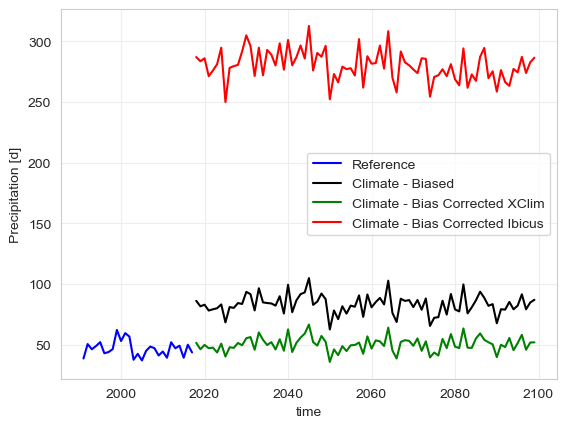

In [183]:
xclim.indices.wetdays(da_reanalysis_data, thresh="10 mm/d").mean(["lat", "lon"]).plot(color="blue", label="Reference")
xclim.indices.wetdays(da_climate_model_data_ch_future, thresh="10 mm/d").mean(["lat", "lon"]).plot(color="black", label="Climate - Biased")
xclim.indices.wetdays(ds_bc_xclim, thresh="10 mm/d").mean(["lat", "lon"]).plot(color="green", label="Climate - Bias Corrected XClim")
xclim.indices.wetdays((ds_bc * 86400), thresh="10 mm/d").mean(["lat", "lon"]).plot(color="red", label="Climate - Bias Corrected Ibicus")
plt.legend()
plt.show()

**Histogram**

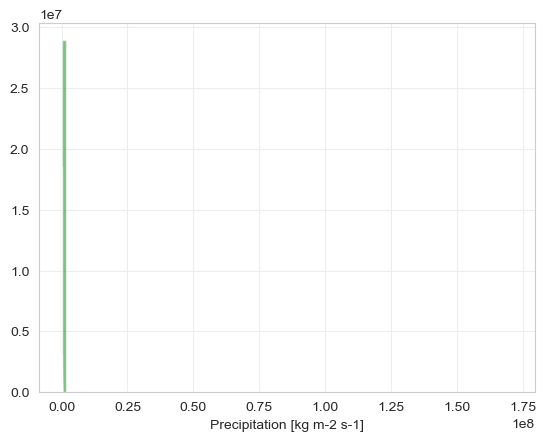

In [152]:
ds_bc_xclim.transpose("time", "lat", "lon").plot(bins=100, alpha=0.5, color="green")
(ds_bc * 86400).plot(bins=100, alpha=0.5, color="red")
plt.show()

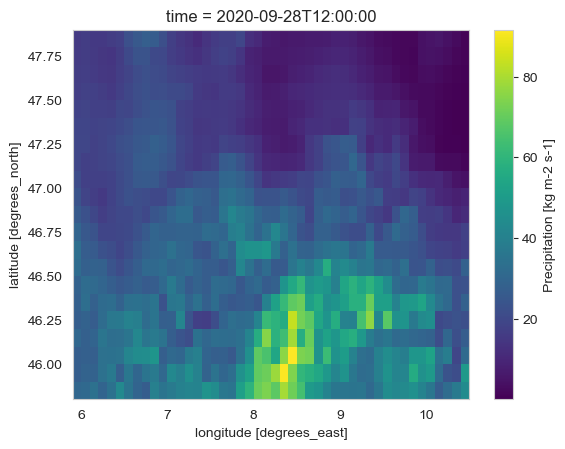

In [132]:
(ds_bc * 86400).isel(time=1000).plot()

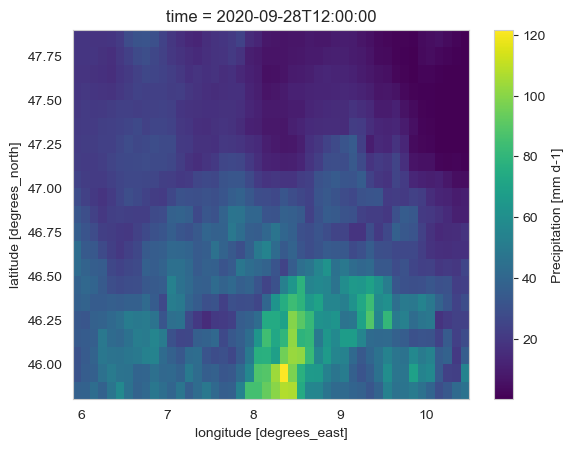

In [130]:
ds_bc_xclim.isel(time=1000).plot()

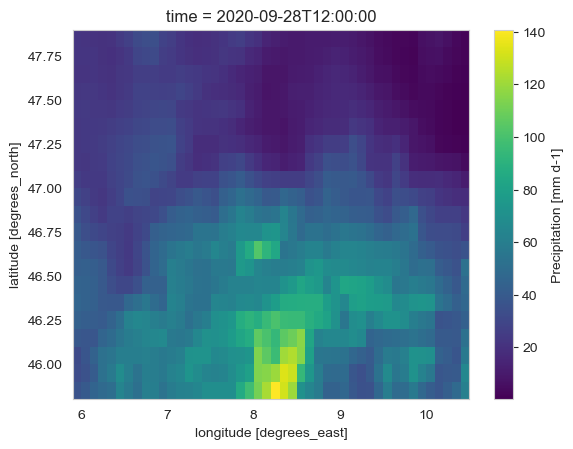

In [131]:
da_climate_model_data_ch_future.isel(time=1000).plot()

## Load bias-corrected data

In [4]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}

In [19]:
ds_pr = ClimateModelData(path_data_processed / 
                         "cordex_processed" / 
                         "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85" / 
                         "regridded" / 
                         "day" / 
                         "pr.zarr", 
                         extent=extent).ds_data.sel(time=slice("2018", None)).load()
ds_pr["pr"] = ds_pr["pr"] * 86400
ds_pr.pr.attrs["units"] = "mm d-1"

In [20]:
ds_pr_bc = ClimateModelData(path_data_processed / 
                            "cordex_processed" / 
                            "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85" / 
                            "bias_corrected" / 
                            "day" / 
                            "pr.zarr", 
                            extent=extent).ds_data.load()
ds_pr_bc.pr.attrs["units"] = "mm d-1"

In [21]:
ds_tp = ClimateModelData(path_data_processed / "cerra_processed" / "regridded" / "tp.zarr", extent=extent).ds_data.load()
ds_tp.tp.attrs["units"] = "mm d-1"

### pr bias correction comparison

**Quantiles**

In [ ]:
quantiles = np.arange(0.01, 1, 0.01)
ds_tp.tp.quantile(quantiles).plot(color="blue", label="Reanalysis")
ds_pr.pr.quantile(quantiles).plot(color="black", label="Future Climate - Biased")
ds_pr_bc.pr.quantile(quantiles).plot(color="green", label="Future Climate - Bias Corrected")
plt.legend()
plt.show()

**Dry-day frequency**

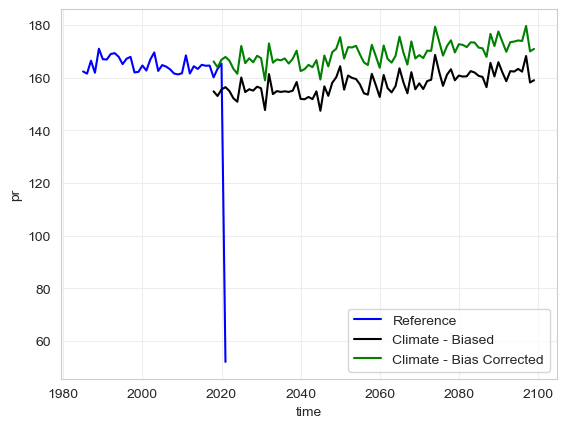

In [22]:
xclim.indices.dry_days(ds_tp.tp, thresh='0.1 mm/d', freq='YS', op='<').mean(["lat", "lon"]).plot(color="blue", label="Reference")
xclim.indices.dry_days(ds_pr.pr, thresh='0.1 mm/d', freq='YS', op='<').mean(["lat", "lon"]).plot(color="black", label="Climate - Biased")
xclim.indices.dry_days(ds_pr_bc.pr, thresh='0.1 mm/d', freq='YS', op='<').mean(["lat", "lon"]).plot(color="green", label="Climate - Bias Corrected")
plt.legend()
plt.show()

**Very wet days**

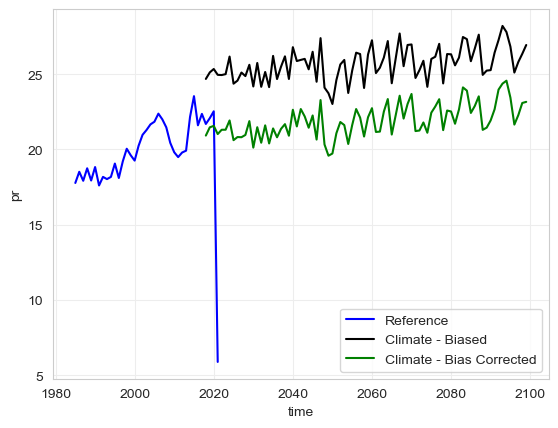

In [23]:
xclim.indices.wetdays(ds_tp.tp, thresh="10 mm/d").mean(["lat", "lon"]).plot(color="blue", label="Reference")
xclim.indices.wetdays(ds_pr.pr, thresh="10 mm/d").mean(["lat", "lon"]).plot(color="black", label="Climate - Biased")
xclim.indices.wetdays(ds_pr_bc.pr, thresh="10 mm/d").mean(["lat", "lon"]).plot(color="green", label="Climate - Bias Corrected")
plt.legend()
plt.show()

**Histogram**

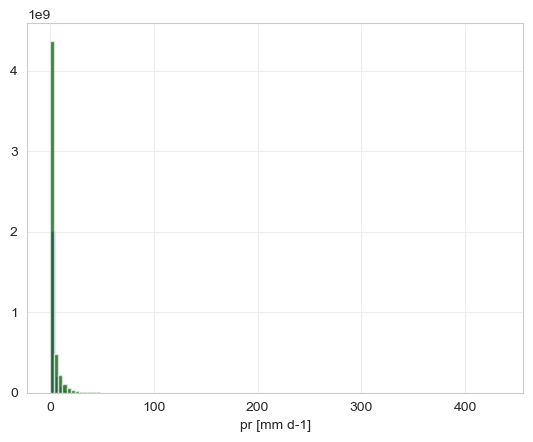

In [25]:
ds_tp.tp.plot(bins=100, alpha=0.5, color="blue", label="Reference")
ds_pr.pr.plot(bins=100, alpha=0.5, color="black", label="Climate - Biased")
ds_pr.pr.plot(bins=100, alpha=0.5, color="green", label="Climate - Bias Corrected")
plt.show()